<a href="https://colab.research.google.com/github/Kokilakoki8398/Kokila/blob/main/Breast_cancer_prediction_100_beats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing

## Import Library

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## Import CSV And convert to DataFrame

In [4]:
import os
import pandas as pd

path = '/kaggle/input/datasets/mobeenfatimah/breast-cancer-prediction-dataset-10000-patient/breast_cancer_prediction.csv'

if 'df' in globals():
    print("DataFrame already exists in runtime memory.")
elif os.path.exists(path):
    df = pd.read_csv(path)
    print("Loaded dataset from the specified path.")
else:
    print("Dataset path not found. Please verify the environment or upload your CSV.")

Dataset path not found. Please verify the environment or upload your CSV.


# Preprocessing

## Frist five row

In [6]:
pd.set_option('display.max_columns', None)
if 'df' in globals():
    print(df.head())
else:
    print("DataFrame 'df' is not defined. Please load the dataset successfully first.")

DataFrame 'df' is not defined. Please load the dataset successfully first.


## last Five row

In [ ]:
df.tail()

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,Tumor_Size_cm,Lymph_Node_Involvement,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
9995,109996,84,Female,31.4,No,No,Yes,High,No,Post,Positive,1.46,No,Normal,Benign,No Cancer,0,117,166,No,5,Not Applicable,46779
9996,109997,43,Female,24.7,No,Yes,No,Moderate,Yes,Pre,Negative,1.16,No,Abnormal,Benign,No Cancer,0,116,169,No,7,No,110807
9997,109998,23,Female,26.2,Yes,No,Yes,Moderate,No,Pre,Negative,1.22,No,Normal,Benign,No Cancer,0,140,214,No,6,No,126164
9998,109999,44,Female,21.8,No,No,No,Moderate,No,Post,Positive,3.05,No,Abnormal,Benign,No Cancer,0,153,175,No,4,Not Applicable,89761
9999,110000,26,Female,31.3,No,Yes,No,Moderate,No,Pre,Negative,3.93,No,Normal,Benign,No Cancer,0,141,231,Yes,4,Yes,40009


## Shape of our dataset

In [9]:
if 'df' in globals():
    print(df.shape)
else:
    print("DataFrame 'df' is not defined. Make sure the dataset is loaded successfully.")

DataFrame 'df' is not defined. Make sure the dataset is loaded successfully.


## List out all columns

In [11]:
if 'df' in globals():
    print(df.columns)
else:
    print("DataFrame 'df' is not defined. Please load the dataset successfully first.")

DataFrame 'df' is not defined. Please load the dataset successfully first.


## Datatype of each columns

In [ ]:
df.dtypes

Patient_ID                  int64
Age                         int64
Gender                     object
BMI                       float64
Family_History             object
Smoking                    object
Alcohol_Consumption        object
Physical_Activity          object
Hormone_Therapy            object
Menopause_Status           object
Genetic_Mutation           object
Tumor_Size_cm             float64
Lymph_Node_Involvement     object
Mammogram_Result           object
Biopsy_Result              object
Cancer_Stage               object
Cancer                      int64
Blood_Pressure              int64
Cholesterol                 int64
Diabetes                   object
Exercise_Days_Per_Week      int64
Breastfeeding_History      object
Annual_Income_USD           int64
dtype: object

## Information of all Columns

In [13]:
if 'df' in globals():
    df.info()
else:
    print("DataFrame 'df' is not defined. Please verify your dataset load step first.")

DataFrame 'df' is not defined. Please verify your dataset load step first.


## Check Null Value

In [ ]:
df.isnull().sum()

Patient_ID                  0
Age                         0
Gender                      0
BMI                       300
Family_History              0
Smoking                     0
Alcohol_Consumption       300
Physical_Activity         300
Hormone_Therapy           300
Menopause_Status            0
Genetic_Mutation            0
Tumor_Size_cm             300
Lymph_Node_Involvement      0
Mammogram_Result            0
Biopsy_Result               0
Cancer_Stage                0
Cancer                      0
Blood_Pressure              0
Cholesterol                 0
Diabetes                    0
Exercise_Days_Per_Week      0
Breastfeeding_History       0
Annual_Income_USD           0
dtype: int64

## Fill missing numerical values with the median

In [15]:
if 'df' in globals():
    df["BMI"] = df["BMI"].fillna(df["BMI"].median())
    df["Tumor_Size_cm"] = df["Tumor_Size_cm"].fillna(
        df["Tumor_Size_cm"].median()
    )
    print("Successfully filled missing numerical values with median.")
else:
    print("DataFrame 'df' is not defined. Please ensure the dataset is successfully loaded first.")

DataFrame 'df' is not defined. Please ensure the dataset is successfully loaded first.


## Fill missing categorical values with the most frequent value

In [18]:
if 'df' in globals():
    df["Alcohol_Consumption"] = df["Alcohol_Consumption"].fillna(
        df["Alcohol_Consumption"].mode()[0]
    )

    df["Physical_Activity"] = df["Physical_Activity"].fillna(
        df["Physical_Activity"].mode()[0]
    )

    df["Hormone_Therapy"] = df["Hormone_Therapy"].fillna(
        df["Hormone_Therapy"].mode()[0]
    )
    print("Successfully filled missing categorical values with mode.")
else:
    print("DataFrame 'df' is not defined. Please ensure the dataset is successfully loaded first.")

DataFrame 'df' is not defined. Please ensure the dataset is successfully loaded first.


## Check missing values after handling them

In [21]:
if 'df' in globals():
    print("\nMissing values after handling:")
    print(df.isnull().sum())
else:
    print("DataFrame 'df' is not defined. Please verify your dataset load step first.")

DataFrame 'df' is not defined. Please verify your dataset load step first.


## Check Dupicate Value

In [23]:
if 'df' in globals():
    print(df.duplicated().sum())
else:
    print("DataFrame 'df' is not defined. Please load the dataset successfully first.")

DataFrame 'df' is not defined. Please load the dataset successfully first.


## Summary

In [ ]:
df.describe()

,Patient_ID,Age,BMI,Tumor_Size_cm,Cancer,Blood_Pressure,Cholesterol,Exercise_Days_Per_Week,Annual_Income_USD
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,105000.50000,52.033800,27.049690,2.626724,0.193300,134.811100,214.071500,3.535200,82337.305000
std,2886.89568,18.789517,4.426572,1.565893,0.394906,26.174742,49.242034,2.282385,39102.629984
min,100001.00000,20.000000,11.100000,0.000000,0.000000,90.000000,130.000000,0.000000,15002.000000
25%,102500.75000,36.000000,24.100000,1.400000,0.000000,112.000000,172.000000,2.000000,48145.750000
50%,105000.50000,52.000000,27.000000,2.510000,0.000000,135.000000,213.000000,4.000000,81813.500000
75%,107500.25000,68.000000,30.000000,3.680000,0.000000,157.000000,257.000000,6.000000,116217.500000
max,110000.00000,84.000000,44.100000,9.880000,1.000000,180.000000,300.000000,7.000000,149996.000000


# EDA

In [24]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

In [32]:
if 'df' in globals():
    fig = plt.figure(figsize=(10,6))
    sns.countplot(data=df, x='Cancer', hue='Gender')
    plt.title(f'{plot_no}. Cancer Distribution Across Gender')
    show_fig()
    plot_no += 1
else:
    print("DataFrame 'df' is not defined. Please load the dataset successfully first.")

DataFrame 'df' is not defined. Please load the dataset successfully first.


In [34]:
if 'df' in globals():
    fig = plt.figure(figsize=(10,6))
    sns.histplot(data=df, x='Age', hue='Cancer', bins=20, kde=True)
    plt.title(f'{plot_no}. Age Distribution by Cancer Status')
    show_fig()
    plot_no += 1
else:
    print("DataFrame 'df' is not defined. Please load the dataset successfully first.")

DataFrame 'df' is not defined. Please load the dataset successfully first.


In [37]:
if 'df' in globals():
    fig = plt.figure(figsize=(10,6))
    sns.boxplot(data=df, x='Cancer', y='BMI')
    plt.title(f'{plot_no}. BMI Comparison Between Cancer Groups')
    show_fig()
    plot_no += 1
else:
    print("DataFrame 'df' is not defined. Please load the dataset successfully first.")

DataFrame 'df' is not defined. Please load the dataset successfully first.


In [39]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer', y='Tumor_Size_cm')
plt.title(f'{plot_no}. Tumor Size Distribution by Cancer Diagnosis')
show_fig()
plot_no += 1

NameError: name 'df' is not defined

<Figure size 1000x600 with 0 Axes>

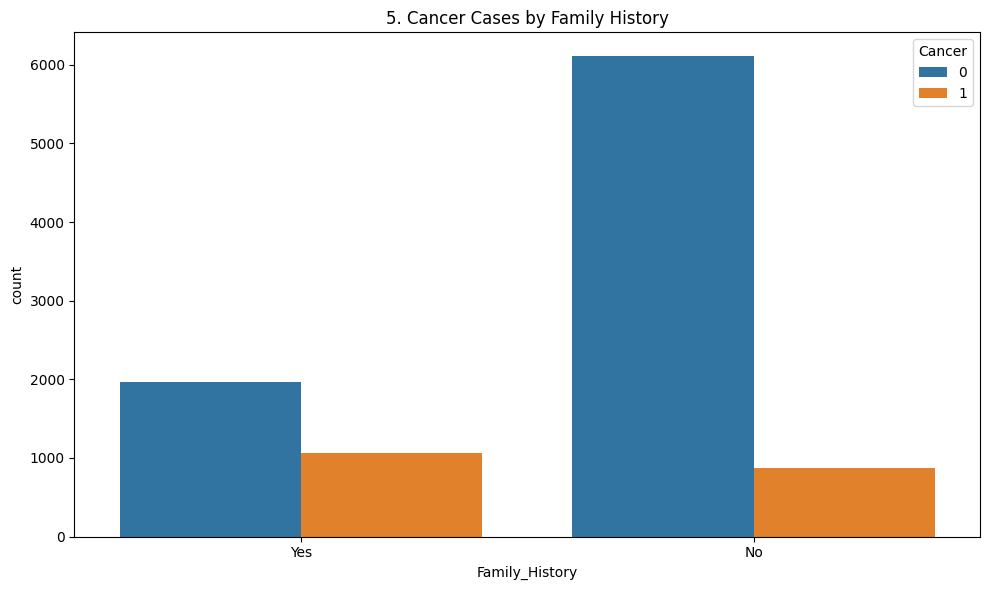

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Family_History', hue='Cancer')
plt.title(f'{plot_no}. Cancer Cases by Family History')
show_fig()
plot_no += 1

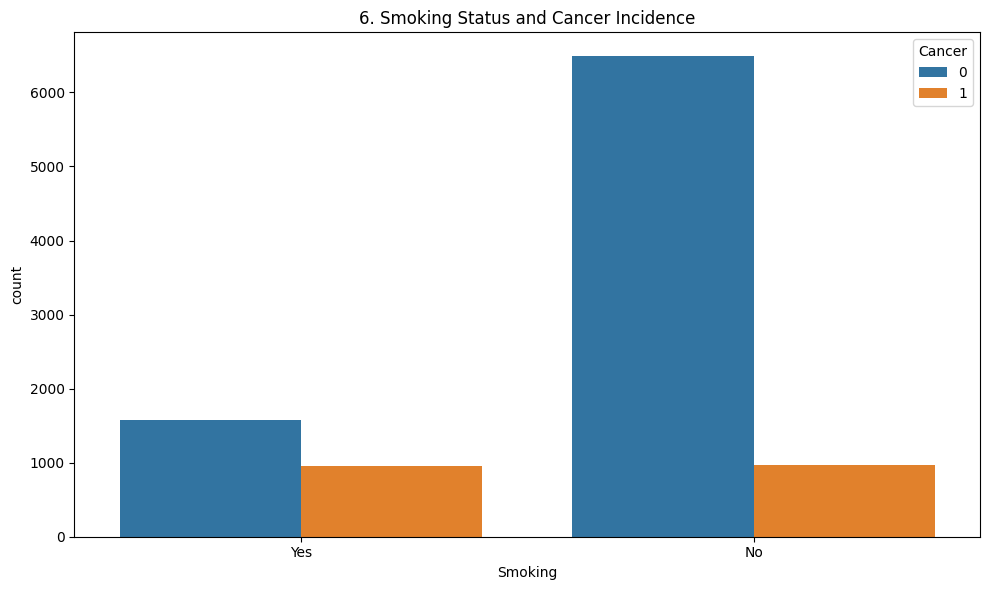

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Smoking', hue='Cancer')
plt.title(f'{plot_no}. Smoking Status and Cancer Incidence')
show_fig()
plot_no += 1

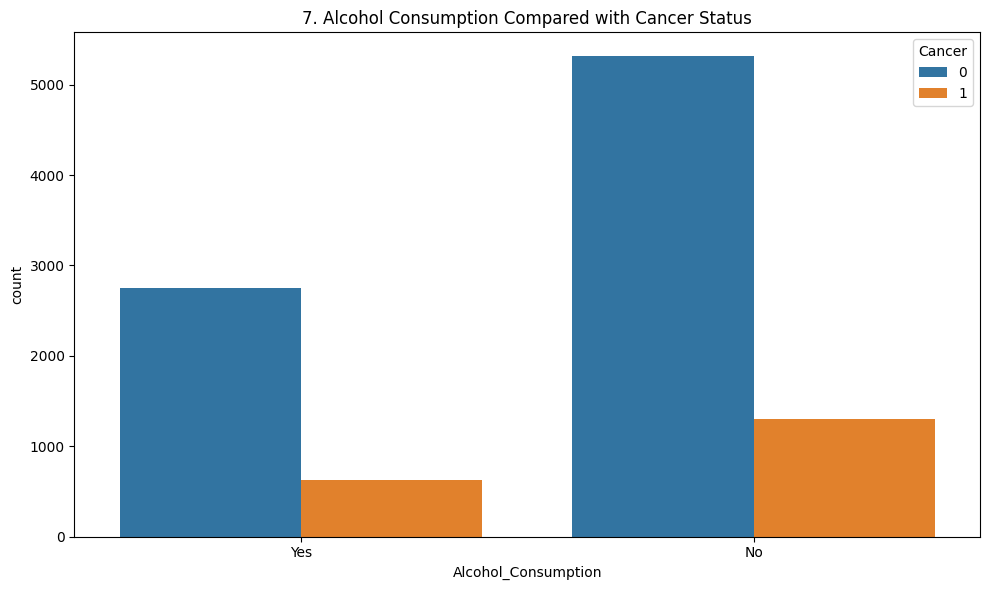

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Alcohol_Consumption', hue='Cancer')
plt.title(f'{plot_no}. Alcohol Consumption Compared with Cancer Status')
show_fig()
plot_no += 1

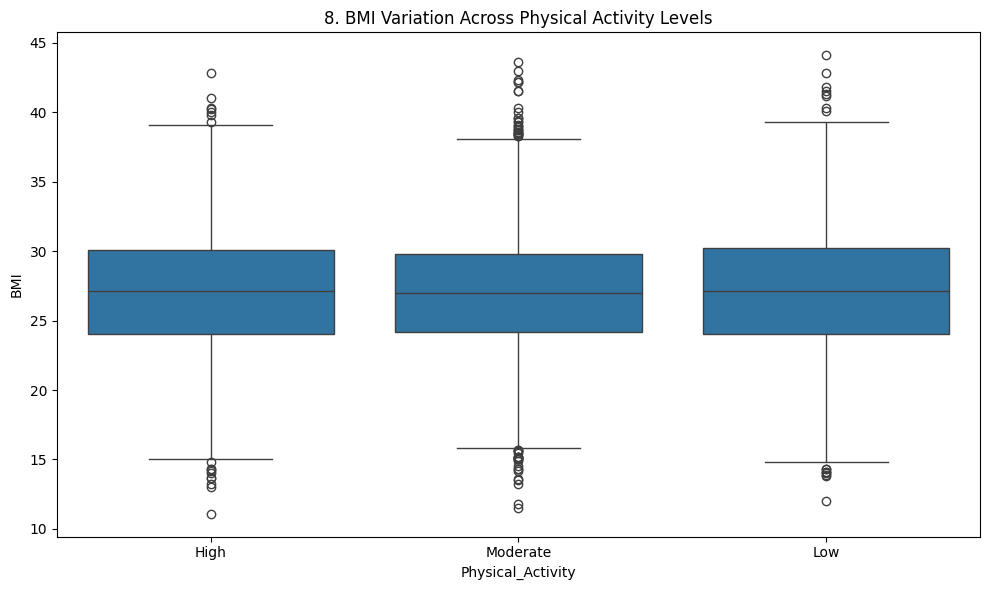

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Physical_Activity', y='BMI')
plt.title(f'{plot_no}. BMI Variation Across Physical Activity Levels')
show_fig()
plot_no += 1

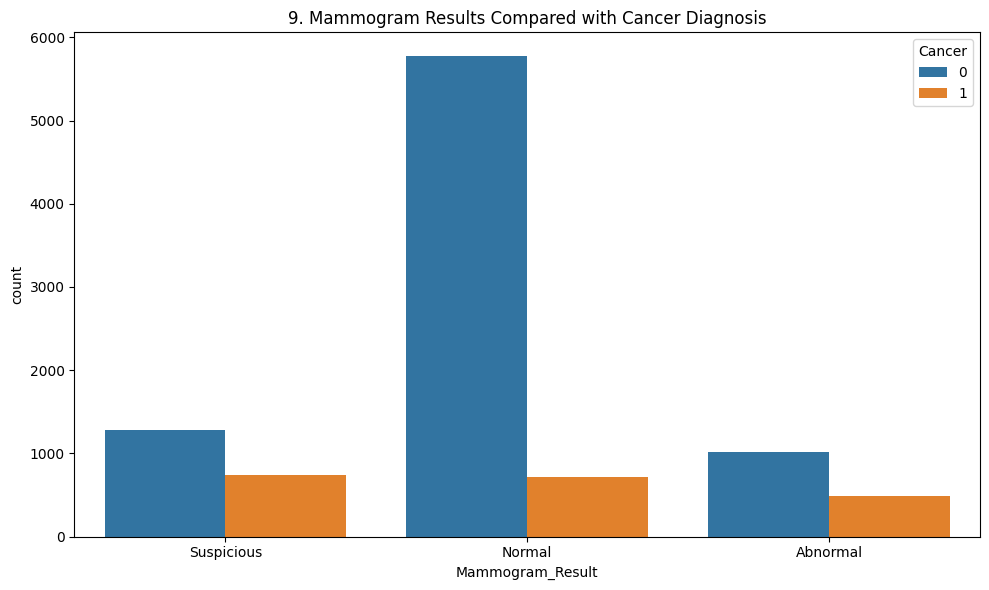

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Mammogram_Result', hue='Cancer')
plt.title(f'{plot_no}. Mammogram Results Compared with Cancer Diagnosis')
show_fig()
plot_no += 1

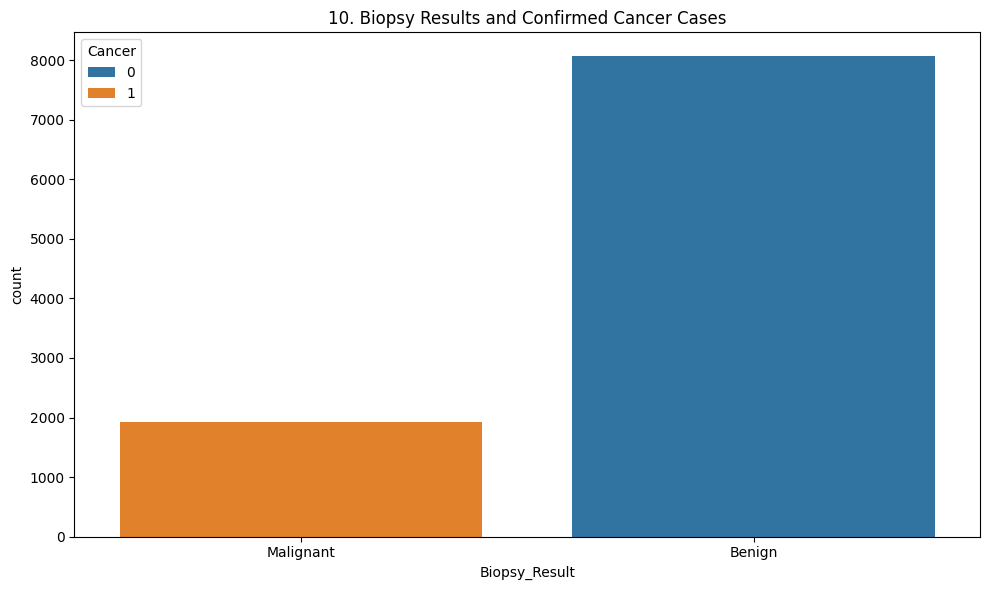

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Biopsy_Result', hue='Cancer')
plt.title(f'{plot_no}. Biopsy Results and Confirmed Cancer Cases')
show_fig()
plot_no += 1

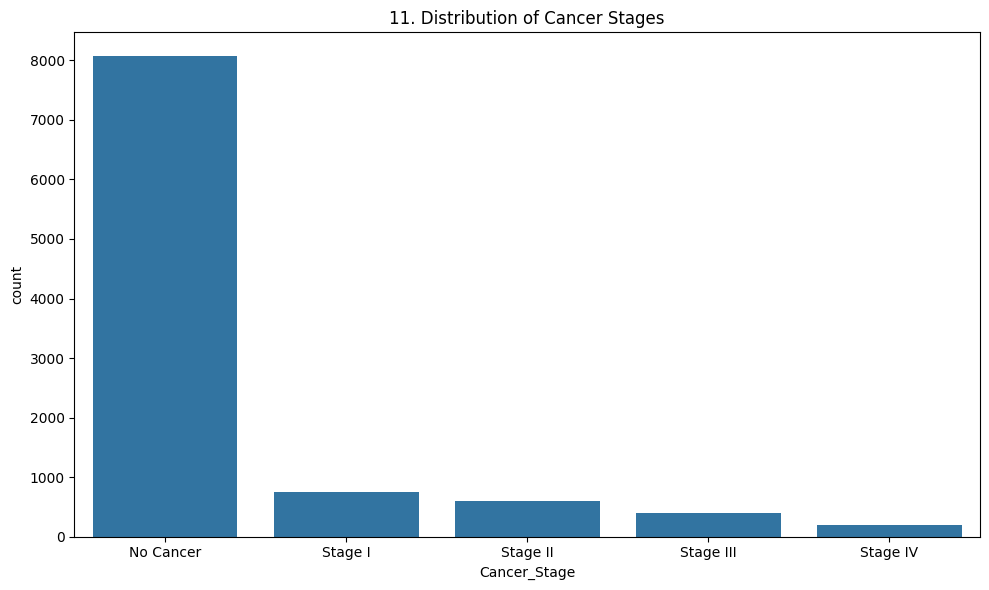

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Cancer_Stage', order=df['Cancer_Stage'].value_counts().index)
plt.title(f'{plot_no}. Distribution of Cancer Stages')
show_fig()
plot_no += 1

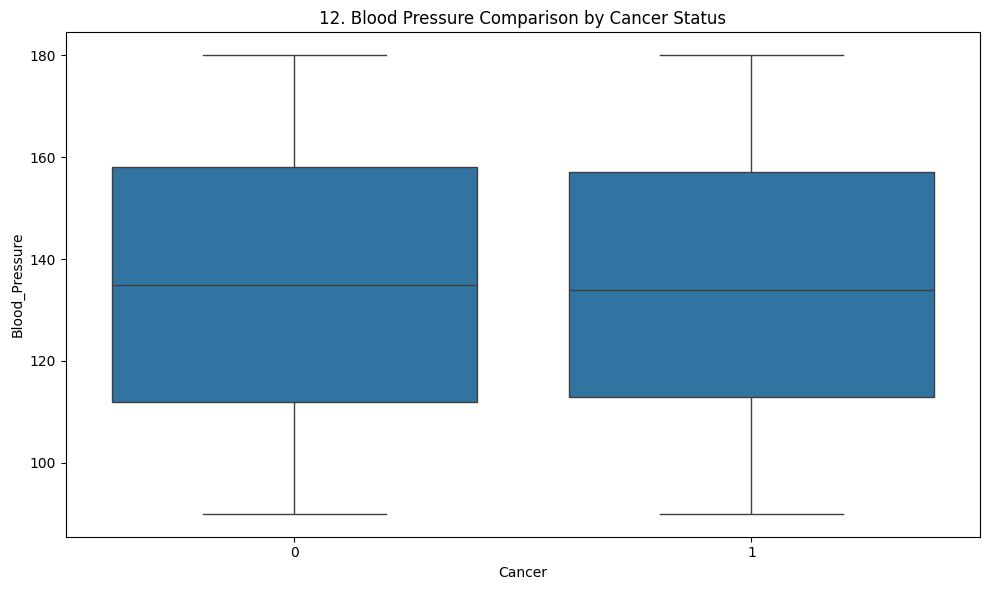

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer', y='Blood_Pressure')
plt.title(f'{plot_no}. Blood Pressure Comparison by Cancer Status')
show_fig()
plot_no += 1

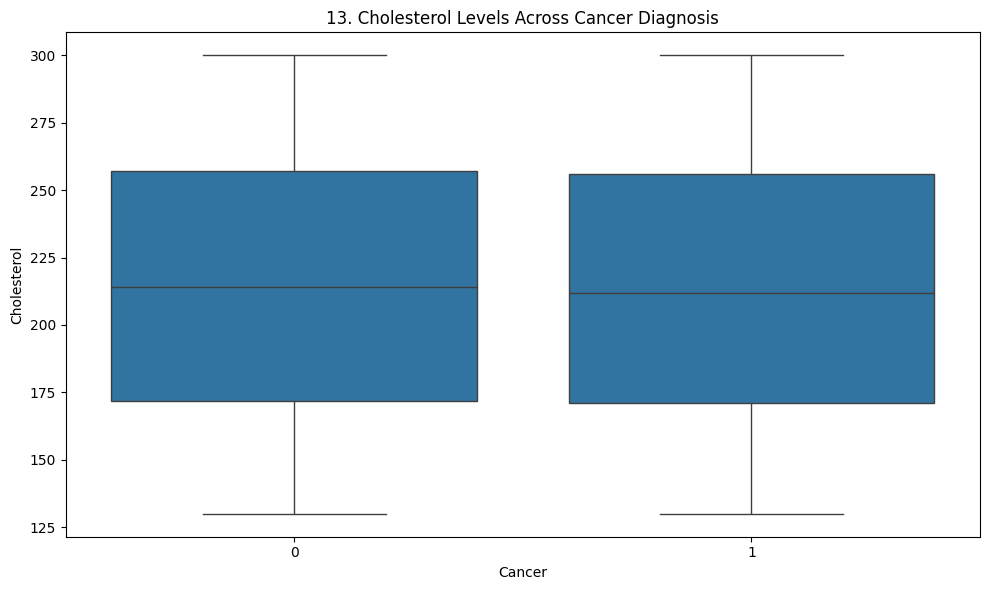

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer', y='Cholesterol')
plt.title(f'{plot_no}. Cholesterol Levels Across Cancer Diagnosis')
show_fig()
plot_no += 1

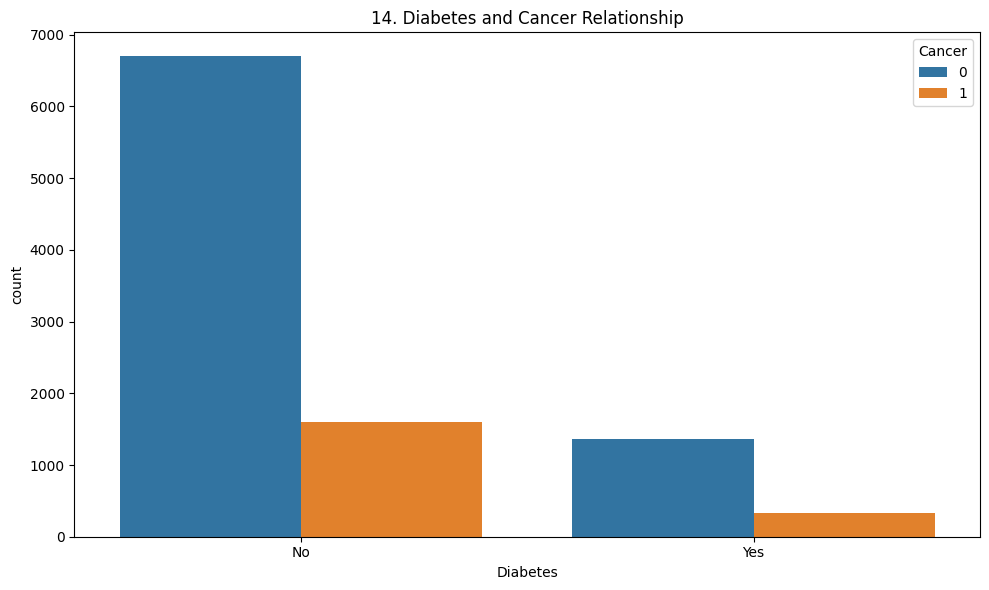

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Diabetes', hue='Cancer')
plt.title(f'{plot_no}. Diabetes and Cancer Relationship')
show_fig()
plot_no += 1

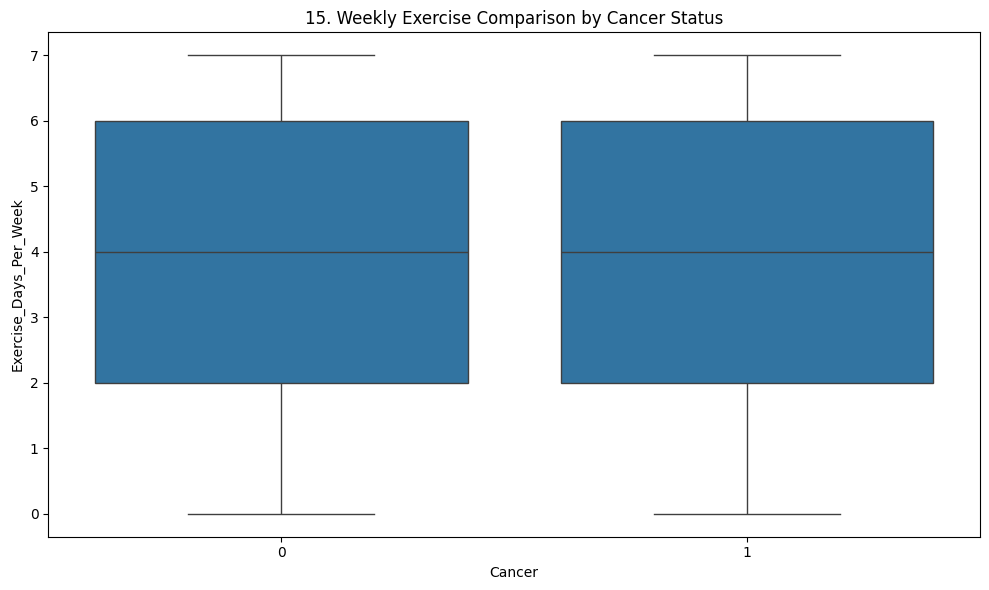

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer', y='Exercise_Days_Per_Week')
plt.title(f'{plot_no}. Weekly Exercise Comparison by Cancer Status')
show_fig()
plot_no += 1

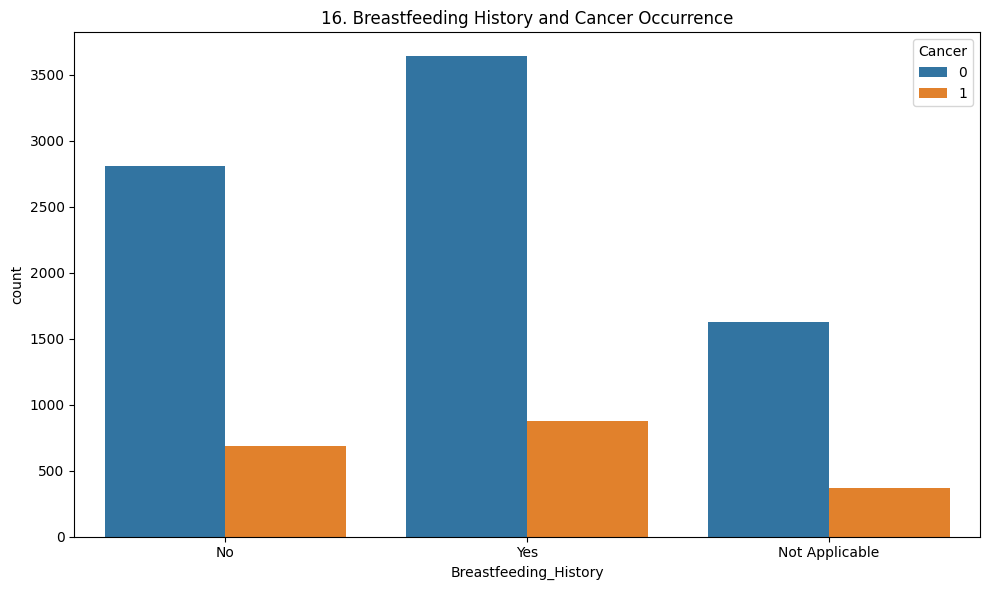

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Breastfeeding_History', hue='Cancer')
plt.title(f'{plot_no}. Breastfeeding History and Cancer Occurrence')
show_fig()
plot_no += 1

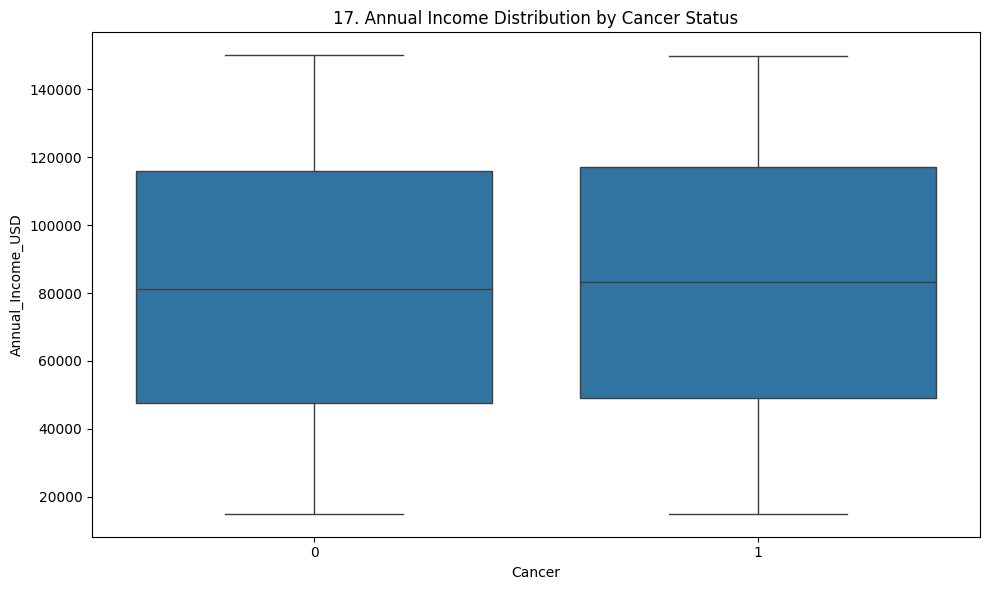

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer', y='Annual_Income_USD')
plt.title(f'{plot_no}. Annual Income Distribution by Cancer Status')
show_fig()
plot_no += 1

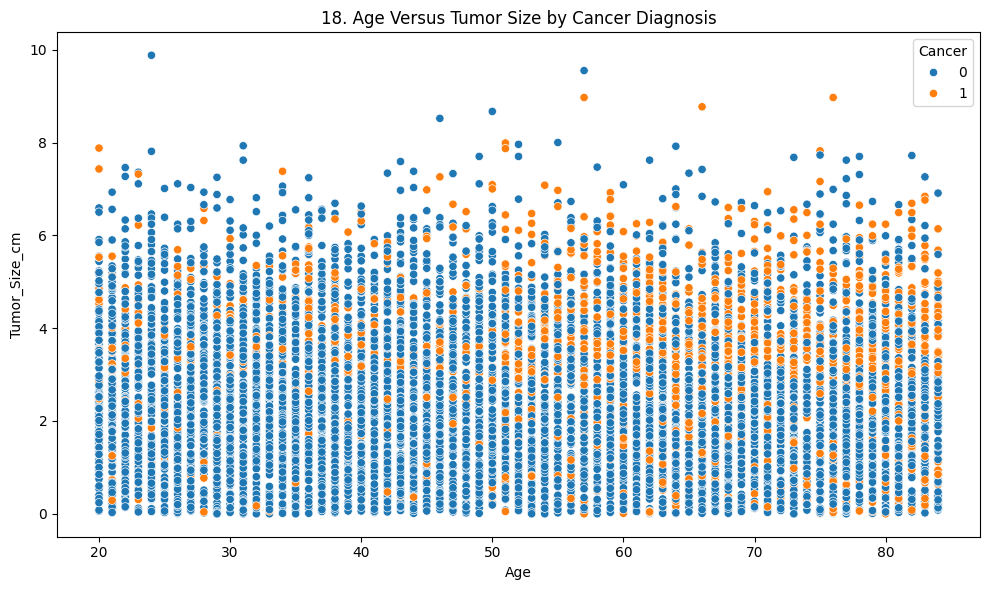

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Age', y='Tumor_Size_cm', hue='Cancer')
plt.title(f'{plot_no}. Age Versus Tumor Size by Cancer Diagnosis')
show_fig()
plot_no += 1

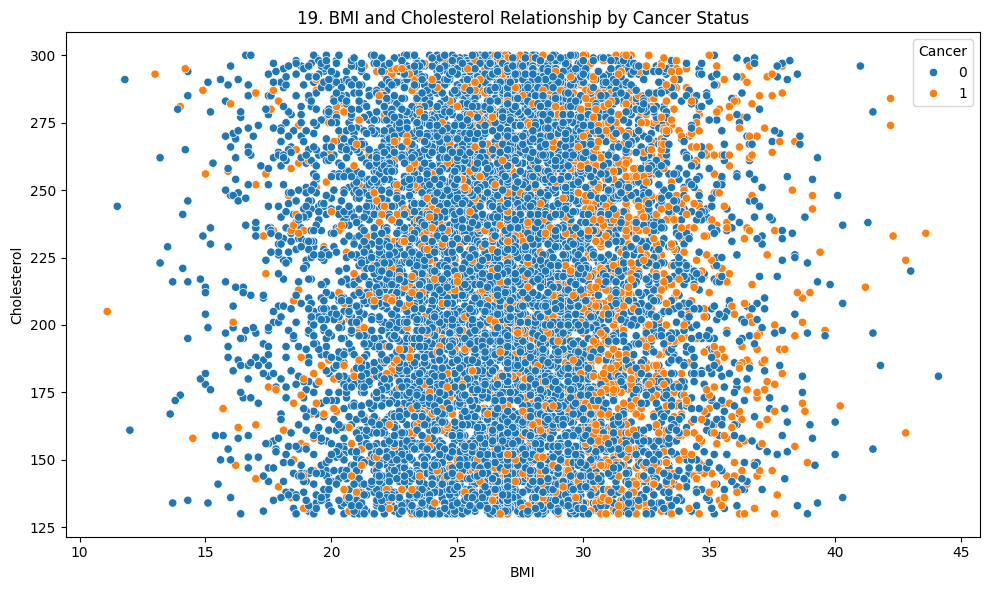

In [ ]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='BMI', y='Cholesterol', hue='Cancer')
plt.title(f'{plot_no}. BMI and Cholesterol Relationship by Cancer Status')
show_fig()
plot_no += 1

# Model Training

## Select target column

In [ ]:
target = "Cancer"

## Prepare features and target

In [ ]:
X = df.drop(columns=[target])
y = df[target]

## Identify numeric and categorical columns

In [ ]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

## Create preprocessing pipeline

In [ ]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

## Split dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Create model pipeline

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_depth=8,
        max_iter=300,
        random_state=42
    ))
])

## Train model

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Patient_ID', 'Age', 'BMI', 'Tumor_Size_cm', 'Blood_Pressure',
       'Cholesterol', 'Exercise_Days_Per_Week', 'Annual_Income_USD'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImpute...
                                                  Index(['Gender', 'Family_History', 'Smoking', 'Alcohol_Consumption',
       'Physical_Activity', 'Hormone_Therapy', 'Menopause_Status',
       'Genetic_Mutation', 'Lymph_Node_Involvement', 'Mammogram_Result',
       'Biopsy_Result', 'Cancer_Stage', 'Diabetes', 'Breastfeeding_History'],
      dtype='object'))])),
                ('classifier',
                 HistGradientBoostingClassifier(learning_rate=0.08, max_depth=8,
                                                max_iter=300,
                                                random_state=42))])

## Predict test data

In [ ]:
y_pred = model.predict(X_test)

## Calculate accuracy

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}")

Model Accuracy: 100.00%


## Plot confusion matrix

<Figure size 700x600 with 0 Axes>

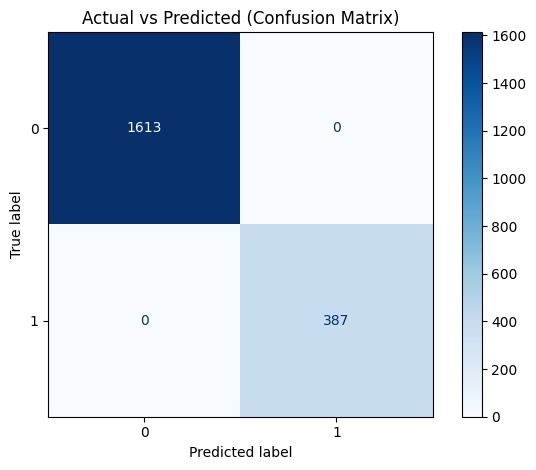

In [ ]:
fig = plt.figure(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)
plt.title("Actual vs Predicted (Confusion Matrix)")
plt.tight_layout()
plt.show()